In [70]:
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import seaborn as sns

In [71]:
import tensorflow as tf

from tensorflow import keras
from keras import layers, models

print(tf.__version__)

2.19.0


In [72]:
# Ocitavanje kategorija
column_names_categories = ['code','parent-code','name']
categories_data = pd.read_csv('categories.csv', names = column_names_categories, na_values = '?', comment='\t', sep=',', skipinitialspace=True, header=0)
categories_data.head()

,code,parent-code,name
0,A,NaN,Misc Expenses
1,B,NaN,Auto & Transport
2,C,NaN,Bills & Utilities
3,D,NaN,Education
4,E,NaN,Entertainment


In [73]:
# Ocitavanje mcc kodova
column_names_mmc = ['code', 'merchant-type']
mcc_data = pd.read_csv('mmc_codes.csv', names = column_names_mmc, na_values = '?', comment='\t', sep=',', skipinitialspace=True, header=0, encoding='cp1252'
)
mcc_data.head()

,code,merchant-type
0,4814,Telecommunication service including local and ...
1,4815,VisaPhone
2,4821,Telegraph services
3,4829,Money Orders - Wire Transfer
4,4899,Cable and other pay television (previously Cab...


In [74]:
def preproccess_data(data_url, labels_url):
  column_names_data = ['id', 'beneficiary-name', 'date', 'direction', 'amount', 'description', 'currency', 'mcc', 'kind']
  dataset = pd.read_csv(data_url, names = column_names_data, na_values = '?', comment='\t', sep=',', skipinitialspace=True, header=0)

  column_names_labels = ['id', 'label']
  labels = pd.read_csv(labels_url, names = column_names_labels, na_values = '?', comment='\t', sep=',', skipinitialspace=True, header=0)

  dataset = pd.merge(dataset, labels, how='inner', on = 'id')  
 
  #amount
  dataset['amount'] = dataset['amount'].map(lambda x : float(str(x).replace(",", "")))
  
  #date => day, month, year

  days = [str(i) + "d" for i in range(1, 32)]
  months = [str(i) + "m" for i in range(1, 13)]

  dataset[["month", "day", "year"]] = dataset["date"].str.split("/", expand=True)
  del dataset['date']
  del dataset['year']
  
  dataset['day'] = dataset['day'].map(lambda x : x + "d")
  dataset['month'] = dataset['month'].map(lambda x : x + "m")

  # handle days as categorical
  unique_days_columns = dataset['day'].unique()

  days_dummy = pd.get_dummies(dataset['day'], prefix='', prefix_sep='')
  dataset = pd.concat([dataset, days_dummy], axis=1, join='inner')

  missing_columns_days = list(set(days) - set(unique_days_columns))
  values = [[0 for i in range(len(missing_columns_days))] for i in range(dataset.shape[0])]
  missing_df_days = pd.DataFrame(values, columns=missing_columns_days)

  dataset = pd.concat([dataset, missing_df_days], axis = 1, join='inner')
  del dataset['day']

  # handle months as categorical

  unique_months_columns = dataset['month'].unique()

  months_dummy = pd.get_dummies(dataset['month'], prefix='', prefix_sep='')
  dataset = pd.concat([dataset, months_dummy], axis=1, join='inner')

  missing_columns_months = list(set(months) - set(unique_months_columns))
  values = [[0 for i in range(len(missing_columns_months))] for i in range(dataset.shape[0])]
  missing_df_months = pd.DataFrame(values, columns=missing_columns_months)

  dataset = pd.concat([dataset, missing_df_months], axis = 1, join='inner')
  del dataset['month']

  #kind
  kinds = ['dep', 'wdw', 'pmt', 'fee', 'inc', 'rev', 'adj', 'lnd', 'lnr', 'fcx', 'aop', 'acl', 'spl', 'sal']
  
  # check nan values
  dataset['kind'] = dataset['kind'].fillna('U')

  # unique columns of given data (can be subset of all kinds)
  unique_kinds_columns = dataset['kind'].unique()
  
  # get dummies
  kind_dummy = pd.get_dummies(dataset['kind'], prefix='', prefix_sep='')
  dataset = pd.concat([dataset, kind_dummy], axis=1, join='inner')

  # handle missing columns from kinds
  missing_columns_kinds = set(kinds) - set(unique_kinds_columns)
  missing_columns_kinds = [str(x) for x in missing_columns_kinds]
  values = [[0 for i in range(len(missing_columns_kinds))] for i in range(dataset.shape[0])]
  missing_df_kinds = pd.DataFrame(values, columns=missing_columns_kinds)

  dataset = pd.concat([dataset, missing_df_kinds], axis = 1, join='inner')

  del dataset['kind']

  #direction
  direction_dummy = pd.get_dummies(dataset['direction'], prefix='', prefix_sep='')
  del dataset['direction']
  dataset = pd.concat([dataset, direction_dummy], axis=1, join='inner')


  # mcc
  
  # fill nan values & convert to int
  dataset['mcc'] = dataset['mcc'].fillna('0')
  dataset = dataset.astype({"mcc" : int})

  unique_columns_mcc = dataset['mcc'].unique()
  
  # get dummies
  mcc_dummy = pd.get_dummies(dataset['mcc'], prefix='', prefix_sep='')
  dataset = pd.concat([dataset, mcc_dummy], axis=1, join='inner')

  # handle missing values from mcc codes
  mcc_data['code'] = mcc_data['code'].astype({"code" : int}) 
  missing_columns_mcc = set(mcc_data['code']) - set(unique_columns_mcc)
  missing_columns_mcc = [str(x) for x in missing_columns_mcc]
  values = [[0 for i in range(len(missing_columns_mcc))] for i in range(dataset.shape[0])]
  missing_df_mcc = pd.DataFrame(values, columns=missing_columns_mcc)

  dataset = pd.concat([dataset, missing_df_mcc], axis = 1, join='inner')
  del dataset['mcc']

  # description
  del dataset['description']
  
  # beneficiary name
  del dataset['beneficiary-name']
  
  # currency
  del dataset['currency']
  
  # id
  del dataset['id']
  
  # IMPORTANT
  dataset = dataset.reindex(sorted(dataset.columns), axis=1)
  return dataset

In [75]:
dataset = preproccess_data("transactions.csv", "train_labels.csv")
dataset.shape

(1303, 314)

In [76]:
X = dataset.drop('label', axis = 1)
y = dataset[['label']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 42)

In [77]:
def build_model(dataset):
  num_classes = int(y_train.max()) + 1
  num_parameters = dataset.shape[1] - 1

  model = models.Sequential()
  model.add(layers.Dense(64, activation='relu', input_dim= num_parameters))
  model.add(layers.Dropout(0.2))
  model.add(layers.Dense(128, activation='relu'))
  model.add(layers.Dropout(0.2))
  model.add(layers.Dense(256, activation='relu'))
  model.add(layers.Dense(num_classes, activation='softmax'))

  optimizer = tf.keras.optimizers.Adam()

  model.compile(loss = tf.keras.losses.CategoricalCrossentropy(),
                optimizer = optimizer,
                metrics=['accuracy'])
  return model

In [78]:
model = build_model(dataset)
model.summary()

C:\Users\praksa\AppData\Local\Temp\ipykernel_13424\2339588238.py:4: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  num_classes = int(y_train.max()) + 1
C:\Users\praksa\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_16 (Dense)                     │ (None, 64)                  │          20,096 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_8 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 107)                 │          27,499 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 88,939 (347.42 KB)

 Trainable params: 88,939 (347.42 KB)

 Non-trainable params: 0 (0.00 B)

In [79]:
# checkpoint
! mkdir models

checkpoint_filepath = '/models/categories_network.weights.h5'
model_checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_filepath,
    save_weights_only=True,
    monitor='val_accuracy',
    mode='max',
    save_best_only=True
)

A subdirectory or file models already exists.


In [80]:
num_classes = int(y_train.max()) + 1

epochs = 100
batch_size = 64

early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience = 25)

train_labels_cat = tf.keras.utils.to_categorical(y_train, num_classes)
test_labels_cat = tf.keras.utils.to_categorical(y_test, num_classes)


# add batch size
history = model.fit(X_train, train_labels_cat, epochs = epochs, batch_size = batch_size, validation_split = 0.2, callbacks=[early_stop, model_checkpoint_callback])
model.load_weights(checkpoint_filepath)

Epoch 1/100


C:\Users\praksa\AppData\Local\Temp\ipykernel_13424\1919405744.py:1: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  num_classes = int(y_train.max()) + 1


13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.0212 - loss: 7.6426 - val_accuracy: 0.3112 - val_loss: 4.5199
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0926 - loss: 5.2936 - val_accuracy: 0.1429 - val_loss: 4.5755
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1212 - loss: 4.9356 - val_accuracy: 0.2806 - val_loss: 4.6559
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.1633 - loss: 4.6856 - val_accuracy: 0.1480 - val_loss: 4.6204
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.0983 - loss: 4.7575 - val_accuracy: 0.3469 - val_loss: 4.3984
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.2792 - loss: 4.7804 - val_accuracy: 0.3418 - val_loss: 4.2712
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.3076 - loss: 4.2066 - val_accuracy: 0.3469 - val_loss: 4.1581
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3003 - loss: 3.9050 - val_accuracy: 0.3469 - val_l

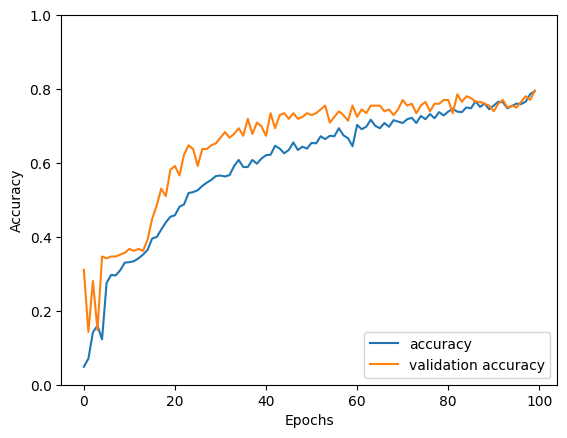

In [81]:
# Evaluation

plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.ylim([0.0, 1])
plt.legend(loc='lower right')

In [82]:
test_loss, test_acc = model.evaluate(X_test, test_labels_cat, verbose=2)

11/11 - 0s - 9ms/step - accuracy: 0.7454 - loss: 0.7673


In [83]:
model = build_model(dataset)

early_stop_epochs = 112

mid_history = model.fit(X_train, train_labels_cat, epochs=early_stop_epochs)

Epoch 1/112


C:\Users\praksa\AppData\Local\Temp\ipykernel_13424\2339588238.py:4: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  num_classes = int(y_train.max()) + 1
C:\Users\praksa\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.0325 - loss: 7.2548
Epoch 2/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2078 - loss: 4.9130
Epoch 3/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2505 - loss: 4.6070
Epoch 4/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3207 - loss: 4.1136
Epoch 5/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3287 - loss: 3.2865
Epoch 6/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3307 - loss: 3.0371
Epoch 7/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3392 - loss: 2.9107
Epoch 8/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3752 - loss: 2.5100
Epoch 9/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3747 - loss: 2.5247
Epoch 10/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4117 - loss: 2.1401
Epoch 11/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4435 - loss: 2.0610
Epoch 12/112
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4868 - lo

In [84]:
test_loss, test_acc = model.evaluate(X_test, test_labels_cat, verbose=2)

11/11 - 0s - 31ms/step - accuracy: 0.7362 - loss: 0.9524


In [85]:
model = build_model(dataset)

early_stop_epochs = 112

y_cat = tf.keras.utils.to_categorical(y, num_classes)


final_history = model.fit(X, y_cat, epochs=early_stop_epochs)

C:\Users\praksa\AppData\Local\Temp\ipykernel_13424\2339588238.py:4: FutureWarning: Calling int on a single element Series is deprecated and will raise a TypeError in the future. Use int(ser.iloc[0]) instead
  num_classes = int(y_train.max()) + 1
C:\Users\praksa\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.0767 - loss: 6.4756
Epoch 2/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.1555 - loss: 4.7257
Epoch 3/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.2277 - loss: 5.2681
Epoch 4/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3342 - loss: 3.9458
Epoch 5/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3233 - loss: 2.9843
Epoch 6/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3599 - loss: 2.7142
Epoch 7/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3466 - loss: 2.7900
Epoch 8/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4189 - loss: 2.2633
Epoch 9/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4427 - loss: 2.0113
Epoch 10/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4833 - loss: 1.9816
Epoch 11/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4962 - loss: 1.7162
Epoch 12/112
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy:

In [92]:
model_path = 'models/categories_network.h5'
model.save(model_path)

! ls models

'ls' is not recognized as an internal or external command,
operable program or batch file.


In [87]:
model = None
model = tf.keras.models.load_model(model_path)
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                     │ (None, 64)                  │          20,096 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_13 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 256)                 │          33,024 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 107)                 │          27,499 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 88,941 (347.43 KB)

 Trainable params: 88,939 (347.42 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [89]:
test_dataset = preproccess_data("transactions.csv", "test_labels.csv")
test_dataset.shape

(200, 314)

In [90]:
X = test_dataset.drop('label', axis=1)
y_test = test_dataset[['label']]

y_cat = tf.keras.utils.to_categorical(y_test, num_classes)

test_loss, test_acc = model.evaluate(X, y_cat, verbose=2)

7/7 - 1s - 81ms/step - accuracy: 0.9000 - loss: 0.2846
